In [72]:
import networkx as nx
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import powerlaw
warnings.filterwarnings('ignore')

In [ ]:
DATA_DIR = "../data_collection/data/"
nodes = pd.read_csv(DATA_DIR + "twitch_nodes.csv")
edges = pd.read_csv(DATA_DIR + "twitch_edgelist.csv")

In [75]:
G = nx.DiGraph()

for _, row in nodes.iterrows():
    G.add_node(row['ID'], 
               label=row['Label'], 
               type=row['Broadcaster_Type'], 
               followers=row['Total_Followers'])
for _, row in edges.iterrows():
    G.add_edge(row['Source'], row['Target'], weight=row['Weight'])

In [ ]:
# selezione top 5000
in_degrees = dict(G.in_degree())
top_5000_nodes = [n for n, deg in sorted(in_degrees.items(), key=lambda item: item[1], reverse=True)[:5000]]
sub_G = G.subgraph(top_5000_nodes)

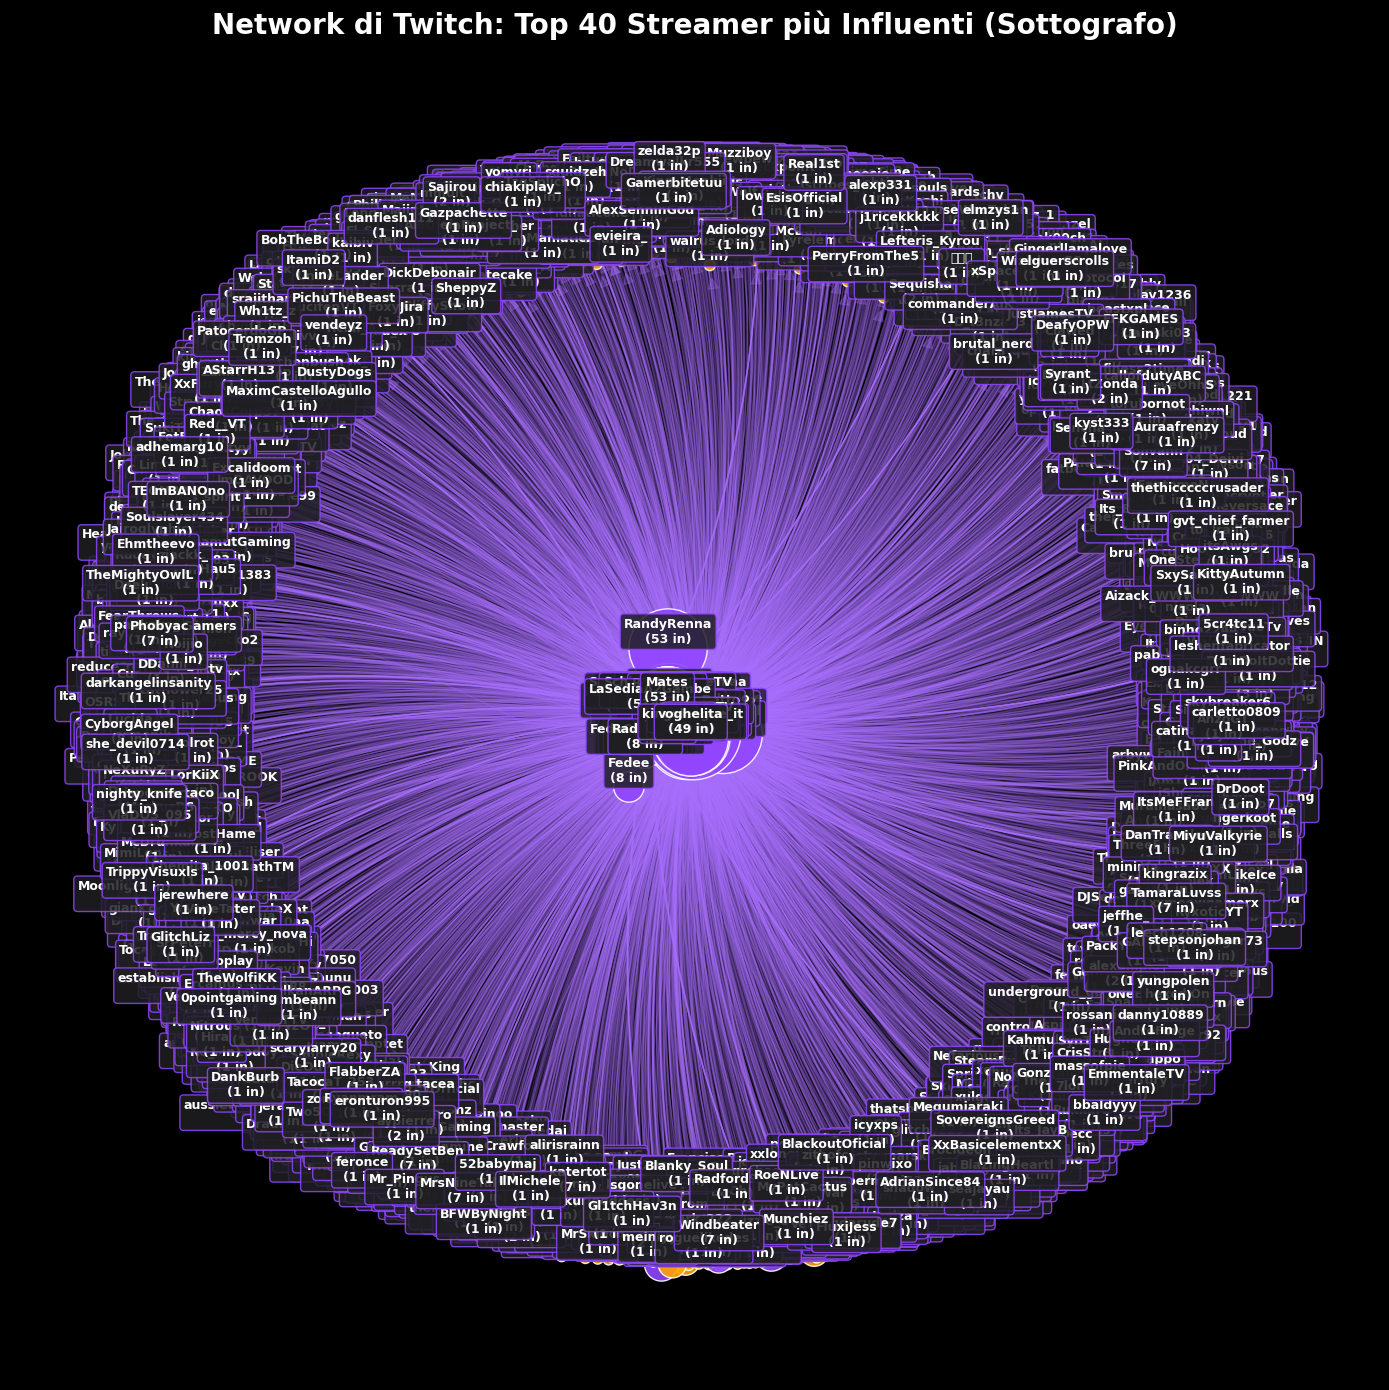

In [78]:
fig, ax = plt.subplots(figsize=(14, 14), facecolor='black')
ax.set_facecolor('black')
pos = nx.spring_layout(sub_G, seed=42)
node_sizes = [G.in_degree(n) * 60 for n in sub_G.nodes]
colors = ['#9146FF' if sub_G.nodes[n]['type'] == 'partner' else '#ffa500' for n in sub_G.nodes]
# 5. Disegno dei Collegamenti (Archi)
nx.draw_networkx_edges(
    sub_G, pos, ax=ax,
    alpha=0.25,                  # Trasparenza per non appesantire la vista
    edge_color='#a970ff',        # Colore violaceo per le linee
    arrows=True, 
    arrowsize=18, 
    arrowstyle='-|>',
    connectionstyle='arc3,rad=0.1' # Rende le linee leggermente curve per gestire i doppi legami
)

# 6. Disegno dei Nodi (Punti)
nx.draw_networkx_nodes(
    sub_G, pos, ax=ax,
    node_size=node_sizes,
    node_color=colors,
    alpha=0.9,
    edgecolors='#ffffff',        # Bordo bianco attorno ai nodi per farli risaltare
    linewidths=1
)
# 7. Aggiunta delle Etichette personalizzate con box di sfondo
for node, (x, y) in pos.items():
    deg = G.in_degree(node)
    label_text = f"{sub_G.nodes[node]['label']}\n({deg} in)"
    ax.text(
        x, y + 0.03,             # Leggero offset verticale rispetto al centro del nodo
        s=label_text,
        color='white',
        fontsize=9,
        fontweight='bold',
        horizontalalignment='center',
        verticalalignment='center',
        bbox=dict(facecolor='#1f1f23', edgecolor='#9146FF', boxstyle='round,pad=0.3', alpha=0.85)
    )


# 8. Titolo e salvataggio del file immagine
ax.set_title("Network di Twitch: Top 40 Streamer più Influenti (Sottografo)", fontsize=20, color='white', fontweight='bold', pad=20)
ax.axis('off') # Nasconde gli assi cartesiani dello sfondo

plt.tight_layout()
plt.show()

In [ ]:
nx.write_gexf(G, "../data_collection/data/twitch_graph_directed.gexf")

# Understanding

In [ ]:
G.number_of_nodes()

10356

In [ ]:
G.number_of_edges()

17433

In [ ]:
G.is_directed()

True

In [ ]:
for deg in G.in_degree():
    if deg[1] > 1:
        print(deg)

(77827128, 49)
(539141014, 49)
(179279586, 49)
(212737350, 49)
(20844000, 49)
(198633705, 49)
(182467649, 49)
(3818382, 49)
(411712420, 49)
(568747744, 49)
(224502550, 49)
(443360331, 49)
(541899730, 49)
(87041939, 49)
(220745733, 49)
(595292180, 49)
(519864232, 49)
(165394505, 49)
(139695853, 49)
(89600394, 49)
(29750090, 49)
(1071644492, 49)
(120112663, 49)
(457571625, 49)
(727053877, 49)
(161787120, 49)
(123293742, 49)
(488181624, 49)
(144274705, 49)
(58587258, 49)
(216906109, 49)
(116434237, 49)
(90752452, 49)
(131070633, 49)
(245910786, 49)
(763632026, 49)
(273316640, 81)
(207277102, 49)
(424894746, 49)
(182810349, 49)
(183637404, 55)
(701179228, 49)
(404813066, 49)
(107379284, 49)
(500640323, 49)
(97552124, 49)
(239570706, 49)
(124318726, 49)
(151120600, 49)
(742520098, 49)
(38499199, 61)
(24354801, 53)
(29673295, 53)
(111040032, 53)
(436730882, 53)
(202948516, 53)
(181713478, 53)
(97171578, 53)
(39432884, 53)
(27319089, 53)
(118985076, 53)
(98700118, 53)
(256447189, 53)
(1569716

In [ ]:
i=0
for deg in G.in_degree():
    if deg[1] == 1:
        i += 1
print(i)

9965


In [ ]:
sum(dict(G.degree()).values())/float(len(G))

3.3667439165701043

In [ ]:
def plot_dist(G):
    # 1. Estraiamo i gradi entranti reali di ciascun nodo
    indegrees = np.array([d for _, d in G.in_degree()])
    
    # Filtriamo i gradi pari a 0 (la legge di potenza e il logaritmo richiedono valori > 0)
    indegrees_filtered = indegrees[indegrees > 0]
    
    # Calcoliamo le frequenze per il grafico di distribuzione P(k)
    degree_counts = np.bincount(indegrees)
    
    # 2. Eseguiamo il fit sui gradi reali (filtrati > 0)
    fit = powerlaw.Fit(indegrees_filtered, fit_method='KS')
    
    # 3. Creazione dei grafici
    fig = plt.figure(figsize=(16, 6)) 
    
    """ Plot Distribution """
    plt.subplot(1, 3, 1)
    # Mostriamo i punti per ogni grado esistente
    plt.plot(range(len(degree_counts)), degree_counts, 'b.')   
    plt.loglog()
    # Impostiamo i limiti corretti sull'asse X (da 1 al grado massimo trovato)
    plt.xlim((1, len(degree_counts)))
    plt.xlabel('Degree (k)')
    plt.ylabel('P(k) [Count]')
    plt.title('Distribuzione dei Gradi (Log-Log)')

    """ Plot CDF """
    plt.subplot(1, 3, 2)
    fit.plot_cdf(color='b', linewidth=2)
    plt.xlabel("Degree (k)")
    plt.ylabel('CDF')
    plt.title('Funzione di Ripartizione (CDF)')

    """ Plot CCDF """
    plt.subplot(1, 3, 3)
    fit.plot_ccdf(color='r', linewidth=2)
    plt.xlabel('Degree (k)')
    plt.ylabel('CCDF (P(X >= k))')
    plt.title('CCDF (Scala Log-Log)')
    
    plt.tight_layout()
    plt.savefig("../figures/in_degree_distribution_directed.png", dpi=150)
    plt.show()

Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 12/12 [00:00<00:00, 728.47it/s]


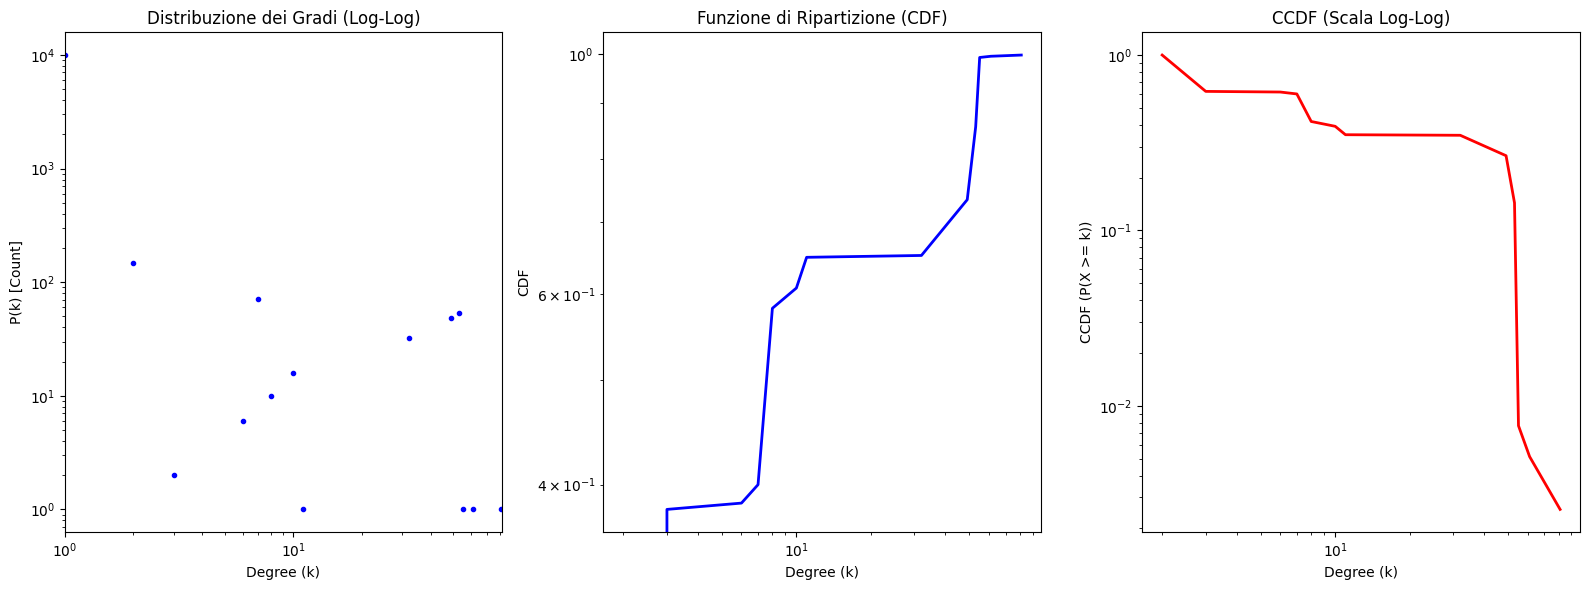

In [ ]:
plot_dist(G)

In [ ]:
#list(G.neighbors(0))

In [85]:
# Se G ha gli ID numerici, lo trasformi in nomi così:
mapping = dict(zip(nodes['ID'], nodes['Label']))
G_name = nx.relabel_nodes(G, mapping)

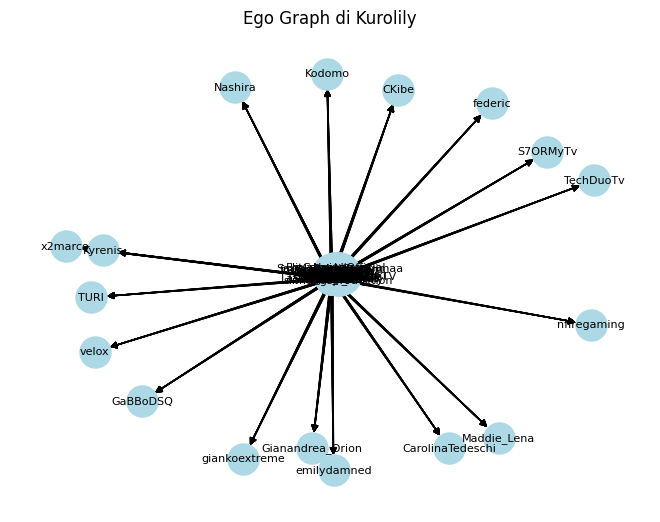

In [87]:
ego = nx.ego_graph(G_name, 'Kurolily', radius=1)
nx.draw(ego, with_labels=True, node_size=500, node_color='lightblue', font_size=8)
plt.title("Ego Graph di Kurolily")
plt.show()

====== ANALISI DELLE COMPONENTI CONNESSE ======

--- COMPONENTI DEBOLMENTE CONNESSE (WEAKLY) ---
Numero totale di isole (componenti deboli): 2
Dimensione della componente gigante (la più grande): 10355 nodi
Dimensione della seconda componente più grande: 1 nodi
--------------------------------------------------

--- COMPONENTI FORTEMENTE CONNESSE (STRONGLY) ---
Numero totale di componenti forti: 10208
Dimensione del nucleo forte più grande: 88 nodi
Dimensione delle successive 4 componenti forti: [62, 1, 1, 1]
--------------------------------------------------

Generazione grafico della seconda componente debole (Nodi: 1)...


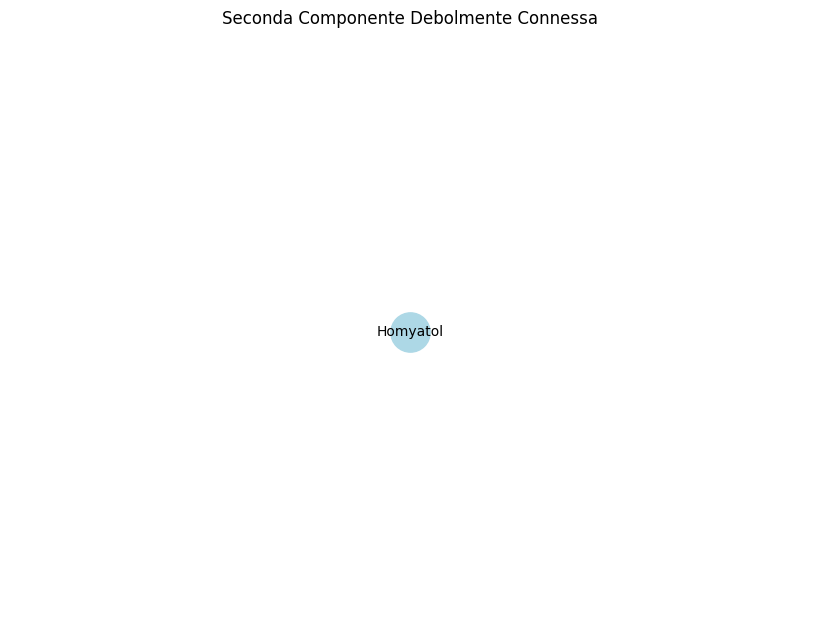

Gli streamer che fanno parte della seconda componente forte più grande sono:
['sbuci', 'BertraTV', 'Darkhim', 'mansi', 'Mates', 'francesca_cuccuru', 'ElitGamingOfficial', 'NOVOEsports', 'PabLOL_VAL', 'Kurolily', 'Crappo_live', 'DogOut_Family', 'Kroatomist', 'delia_', 'Demitat', 'Cydonia_Chiara', 'Parliamodivg', 'ocwsport', 'Rixel_official', 'Yucali', 'LeonasTV', 'Naaklin', 'Gioee', 'iTermosifoni', 'marcofiero', 'Babbalucy', 'MARINO_SKI', 'Fedee', 'Danipitbull', 'Rocket25_', 'Zanzo_Official', 'Totta', 'SchiacciSempreTV', 'Sbriser', 'Poldo', 'Dlarzz', 'Yotobi', 'Sabaku_no_Sutoriimaa', 'Gidano', 'FedeCampoVGC', 'Rad3ontv', 'LeonardoBru', 'GoEaSyTwitch', 'RandyRenna', '151eg', 'pixelkewie', 'ilGattoSulTubo', 'LaSediaA2Gambe', 'Fierik', 'GOA7League', 'danny_lazzarin', 'slimdogsproduction', 'BisUmTo', 'POW3R', 'ErenBlaze', 'InnTale', 'HALtv', 'Phenrir_Mailoki', 'TearlessRaptor', 'Hemerald', 'Terenas', 'SoloUmido']


In [96]:
# Assegna il tuo grafo a una variabile comoda (assumendo sia quello con i nomi)

print("====== ANALISI DELLE COMPONENTI CONNESSE ======\n")

# ==========================================
# 1. WEAKLY CONNECTED COMPONENTS (Deboli)
# ==========================================
# Conta il numero totale di componenti deboli
num_weak = nx.number_weakly_connected_components(G_name)
# Estrae la lista delle componenti e le ordina dalla più grande alla più piccola
weak_comps = sorted(nx.weakly_connected_components(G_name), key=len, reverse=True)

print(f"--- COMPONENTI DEBOLMENTE CONNESSE (WEAKLY) ---")
print(f"Numero totale di isole (componenti deboli): {num_weak}")
print(f"Dimensione della componente gigante (la più grande): {len(weak_comps[0])} nodi")
if len(weak_comps) > 1:
    print(f"Dimensione della seconda componente più grande: {len(weak_comps[1])} nodi")
print("-" * 50 + "\n")


# ==========================================
# 2. STRONGLY CONNECTED COMPONENTS (Forti)
# ==========================================
# Conta il numero totale di componenti forti
num_strong = nx.number_strongly_connected_components(G_name)
# Estrae la lista delle componenti forti e le ordina per dimensione decrescente
strong_comps = sorted(nx.strongly_connected_components(G_name), key=len, reverse=True)

print(f"--- COMPONENTI FORTEMENTE CONNESSE (STRONGLY) ---")
print(f"Numero totale di componenti forti: {num_strong}")
print(f"Dimensione del nucleo forte più grande: {len(strong_comps[0])} nodi")
print(f"Dimensione delle successive 4 componenti forti: {[len(c) for c in strong_comps[1:5]]}")
print("-" * 50 + "\n")


# ==========================================
# 3. ESTRAZIONE E VISUALIZZAZIONE DEI SOTTOGRAFI
# ==========================================

# Esempio A: Estraiamo la seconda componente debole più grande (se esiste ed è piccola)
if len(weak_comps) > 1 and len(weak_comps[1]) < 50:
    print(f"Generazione grafico della seconda componente debole (Nodi: {len(weak_comps[1])})...")
    sub_weak_1 = G_name.subgraph(weak_comps[1])
    
    plt.figure(figsize=(8, 6), facecolor='white')
    nx.draw(sub_weak_1, with_labels=True, node_color='lightblue', edge_color='gray', node_size=800, font_size=10)
    plt.title("Seconda Componente Debolmente Connessa")
    plt.savefig("../figures/second_weak_component.png")
    plt.show()

# Esempio B: Isolare e vedere chi fa parte della seconda componente forte più grande
if len(strong_comps) > 1:
    seconda_componente_forte = list(strong_comps[1])
    print(f"Gli streamer che fanno parte della seconda componente forte più grande sono:")
    print(seconda_componente_forte)

## Paths and Diameter

In [84]:
nx.shortest_path(G_name, source='Kurolily', target='POW3R')

['Kurolily', 'POW3R']

In [88]:
nx.shortest_path_length(G_name, source='Kurolily', target='POW3R')

1

In [98]:
# 1. Trova tutte le componenti fortemente connesse e ordinale dalla più grande alla più piccola
strong_comps = sorted(nx.strongly_connected_components(G_name), key=len, reverse=True)

# 2. Estrai il sottografo della componente gigante (la prima della lista)
G_giant_strong = G_name.subgraph(strong_comps[0])

# 3. Calcola il diametro orientato su questo nucleo centrale
diametro_directed = nx.diameter(G_giant_strong)

print(f"Dimensione del nucleo forte analizzato: {G_giant_strong.number_of_nodes()} nodi")
print(f"Il diametro orientato (directed) del nucleo centrale è: {diametro_directed}")

Dimensione del nucleo forte analizzato: 88 nodi
Il diametro orientato (directed) del nucleo centrale è: 3


## Triangles, density and clustering

In [99]:
nx.density(G)

0.0001625660993032402

In [100]:
#nx.triangles(G_name)[Tumblurr]

In [104]:
nx.clustering(G_name)['Kurolily']

0.7604026845637584

In [102]:
nx.average_clustering(G) 

0.024558391002600342